# V4 Dynamic Coupled Packed-Bed Reactor

## tl;dr

This notebook advances bulk-gas concentrations and H*/CO* coverages as ODE states with a method-of-lines BDF solve. It compares constant and periodic CO feeds, resolves square and sinusoidal forcing over periods from 0.1 to 10 s, and checks the cycle-averaged conversion/selectivity against a constant-CO steady-state envelope. The computed outcome and any limits of the assumed surface-relaxation timescale are reported after execution.

## Context & methods

The V3 engine is vendored at `notebooks/reference/v4/vendor/pbr/`. V4 adds CO to its gas and surface state layouts, Schbib et al. (1996) competitive H/CO adsorption, a finite-volume Danckwerts inlet, and a time-dependent CO inlet hook. The dynamic closure uses `Relaxation`, so gas and coverage accumulation remain in the integrated state; the notebook does not use `AlgebraicEquilibrium`.

The source's Table 8 gives macro-rate and adsorption constants, but not elementary adsorption/desorption rates. The finite surface-memory extension therefore needs an assumed relaxation time. That time is exposed, varied in a sensitivity check, and is not presented as a Schbib kinetic constant. The Schbib table prints `log A_i` without its base; the implementation interprets it as base 10, an explicit unresolved source convention.

### Key assumptions

- Isothermal 341 K, 16 atm operation using the Table 3 feed and 100 cm³(STP)/min flow. CH4 is the untracked balance gas; CO is included in the gas state.
- Bed void fraction 0.45 and a 1 mm pellet diameter are scenario inputs because Schbib does not report these reactor packing quantities in Tables 3–4. Axial dispersion uses the existing Danckwerts correlation `D_ax = 0.018 u_s d_p`; its dependence on the assumed pellet size is reported.
- The pellet uses the well-mixed `Uniform` closure, matching the Schbib paper's neglect of intrapellet gradients. Bulk gas and surface coverage states remain transient.
- CO is modulated around 250 ppm with amplitude 200 ppm, so the feed remains in the 50–450 ppm range. The modulation replaces inert CH4 while holding the other reactive feed fractions fixed.
- Ethylene selectivity is net ethylene formation divided by acetylene consumption. Cycle averages are time averages of instantaneous conversion and selectivity.

Primary source: Schbib, García, Gígola, and Errazu, “Kinetics of Front-End Acetylene Hydrogenation in Ethylene Production,” *Ind. Eng. Chem. Res.* 35 (1996), 1496–1505, Tables 3, 4 and 8, reduced rate equations (24–25). The local source is `research/literature/schbib_1996_extracted_text.txt` and the corresponding PDF/HTML.

## 1. Runtime and model inputs

The species vector is H2, C2H2, C2H4, C2H6, CO. The gas state is concentration per void volume, and the four surface states are H*, C2H2*, C2H4*, and CO*. Schbib's reduced model neglects hydrocarbon adsorption terms; its dynamic surface extension therefore gives C2H2* and C2H4* zero targets.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks" / "reference" / "v4" / "vendor" / "pbr").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the vendored pbr engine")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "reference" / "v4" / "vendor"))

from pbr.closures import NoExternalResistance, Relaxation, Uniform
from pbr.model import Inputs, build_model, periodic_co_inlet
from pbr.parameters import (
    AdvectionScheme, Catalyst, Geometry, OperatingPoint, R_GAS, Schbib1996,
    SolverSettings,
)
from pbr.species import GASES, IGAS

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.grid": True,
    "grid.alpha": 0.23,
    "font.size": 10,
})
print({"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__})
NOTEBOOK_STARTED = time.perf_counter()


{'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0'}


In [2]:
# Schbib Tables 3–4; constants from Table 8.
T_K = 341.0
P_PA = 16.0 * 101325.0
STP_T_K = 273.15
STP_P_PA = 101325.0
FLOW_STP_M3_S = 100.0e-6 / 60.0
F_TOTAL_MOL_S = FLOW_STP_M3_S * STP_P_PA / (R_GAS * STP_T_K)
Q_REACTOR_M3_S = F_TOTAL_MOL_S * R_GAS * T_K / P_PA

BASE_FEED = {"CH4": 6.53, "C2H2": 0.52, "C2H4": 43.99, "C2H6": 26.72, "H2": 22.10}
Y_CO_MEAN = 250.0e-6
base_total = sum(BASE_FEED.values())
FEED_Y = {name: value / base_total * (1.0 - Y_CO_MEAN) for name, value in BASE_FEED.items()}
FEED_Y["CO"] = Y_CO_MEAN

TUBE_ID_M = 0.010                       # Table 3 reactor description
CATALYST_MASS_KG = 1.0e-3              # Table 3 lower end; SV = 100
RHO_APP_KG_M3 = 1610.0                 # Table 4 apparent density
EPS_B = 0.45                           # scenario assumption, not a Table 4 value
EPS_P = 0.545                          # Table 4 porosity
PELLET_DIAMETER_M = 1.0e-3             # scenario assumption for dispersion correlation
AREA_M2 = np.pi * TUBE_ID_M**2 / 4.0
U_SUPERFICIAL_M_S = Q_REACTOR_M3_S / AREA_M2
D_AX_M2_S = 0.018 * U_SUPERFICIAL_M_S * PELLET_DIAMETER_M

# Derived from Table 4: 0.04 wt% Pd and H/Pd = 0.15.
PD_MASS_FRACTION = 0.0004
H_PER_PD = 0.15
PD_MOLAR_MASS_KG_MOL = 106.42e-3
SITE_DENSITY_MOL_KG = PD_MASS_FRACTION / PD_MOLAR_MASS_KG_MOL * H_PER_PD

SURFACE_TAU_S = 0.05                 # explicit exploratory assumption
CO_DELTA_PPM = 200.0
CO_PERIODS_S = np.array([0.1, 0.3, 1.0, 3.0, 10.0])

operating = OperatingPoint(
    temperature=T_K,
    pressure=P_PA,
    volumetric_flow=Q_REACTOR_M3_S,
    mole_fractions=FEED_Y,
)
geometry = Geometry(
    tube_inner_diameter=TUBE_ID_M,
    catalyst_mass=CATALYST_MASS_KG,
    bed_void_fraction=EPS_B,
)
catalyst = Catalyst(
    name="0.04 wt% Pd/alpha-Al2O3 (Schbib Table 4)",
    support="alpha-Al2O3",
    particle_radius=PELLET_DIAMETER_M / 2.0,
    particle_porosity=EPS_P,
    particle_density=RHO_APP_KG_M3,
    tortuosity=1.0,                     # unused by Uniform radial closure
    metal_mass_fraction=PD_MASS_FRACTION,
    site_density=SITE_DENSITY_MOL_KG,
)
kinetics = Schbib1996(
    log_A_kA=31.1, E_kA_kcal_mol=45.51,
    log_A_kE=26.6, E_kE_kcal_mol=42.94,
    log_A_KH=20.2, E_KH_kcal_mol=21.22,
    log_A_KCO=13.6, E_KCO_kcal_mol=9.95,
)

def build_case(surface_tau_s=SURFACE_TAU_S, n_z=32):
    solver = SolverSettings(
        n_axial=n_z,
        n_radial=3,
        radial_geometry=2,
        advection_scheme=AdvectionScheme.UPWIND1,
        axial_dispersion=D_AX_M2_S,
        integrator="BDF",
        rtol=2.0e-6,
        atol=1.0e-12,
        use_sparsity=True,
    )
    inputs = Inputs(
        geometry=geometry,
        catalyst=catalyst,
        operating=operating,
        kinetics=kinetics,
        solver=solver,
        radial=Uniform(),
        external=NoExternalResistance(),
        surface=Relaxation(tau=surface_tau_s),
        axial_dispersion=D_AX_M2_S,
    )
    inlet = periodic_co_inlet(
        operating, mean_ppm=Y_CO_MEAN * 1e6, delta_ppm=0.0,
        period_s=1.0, waveform="square",
    )
    return inputs, build_model(inputs, inlet)

inputs, model = build_case()
BED_LENGTH_M = model.derived.bed_length
GAS_RESIDENCE_S = EPS_B * BED_LENGTH_M / U_SUPERFICIAL_M_S
PE_AXIAL = U_SUPERFICIAL_M_S * BED_LENGTH_M / D_AX_M2_S

input_summary = pd.Series({
    "total feed (mol/s)": F_TOTAL_MOL_S,
    "bed length (m)": BED_LENGTH_M,
    "superficial velocity (m/s)": U_SUPERFICIAL_M_S,
    "gas residence time (s)": GAS_RESIDENCE_S,
    "axial dispersion (m2/s)": D_AX_M2_S,
    "axial Peclet number": PE_AXIAL,
    "surface site density (mol/kgcat)": SITE_DENSITY_MOL_KG,
})
display(input_summary.map(lambda value: f"{value:.4e}").to_frame("value"))


,value
total feed (mol/s),7.4358e-05
bed length (m),1.4379e-02
superficial velocity (m/s),1.6557e-03
gas residence time (s),3.9079e+00
axial dispersion (m2/s),2.9803e-08
axial Peclet number,7.9882e+02
surface site density (mol/kgcat),5.6380e-04


## 2. Transient RHS and Schbib rate checks

For axial cell averages, the solver evaluates `eps_b * dC_b/dt = -div(J) + source`. The Danckwerts inlet sets the total face flux to `u_s C_in(t)`; the outlet uses zero concentration gradient. Surface coverage derivatives exchange H2/CO with the gas inventory using the derived Table 4 site density.

In [3]:
rate = model.rate
c_in = np.asarray(model.inlet(0.0))
p_in = c_in * R_GAS * T_K
theta_target = rate.coverages(p_in, T_K)
equilibrium_result = rate.rates(p_in, T_K)
dynamic_at_equilibrium = rate.rates(p_in, T_K, theta_target)
assert np.allclose(equilibrium_result.gas, dynamic_at_equilibrium.gas, rtol=2e-12, atol=1e-20)

# Check that CO competition enters the cubed denominator and suppresses both rates.
def rates_at_co(co_ppm):
    p = p_in.copy()
    p[IGAS["CO"]] = co_ppm * 1e-6 * P_PA
    return rate.rates(p, T_K).gas

r_low_co = rates_at_co(50.0)
r_high_co = rates_at_co(450.0)
assert abs(r_low_co[IGAS["C2H2"]]) > abs(r_high_co[IGAS["C2H2"]])
assert abs(r_low_co[IGAS["C2H4"]]) > abs(r_high_co[IGAS["C2H4"]])

# True accumulation check from a mildly perturbed, preconditioned catalyst state.
initial_bulk = np.tile(c_in, (model.layout.n_z, 1))
initial_theta = np.tile(theta_target, (model.layout.n_z, 1, 1))
initial_theta[:, 0, 3] += 5.0e-3
y_initial = model.layout.pack(initial_bulk, theta=initial_theta)
dy_initial = model.rhs(0.013, y_initial)
eps_b_dcb_dt = EPS_B * dy_initial[:model.layout.gas_size].reshape(model.layout.n_z, len(GASES))
dtheta_dt = dy_initial[model.layout.gas_size:].reshape(model.layout.n_z, 1, 4)
assert np.max(np.abs(eps_b_dcb_dt)) > 0.0
assert np.max(np.abs(dtheta_dt)) > 0.0

print({
    "maximum |eps_b dC_b/dt| (mol/m3/s)": float(np.max(np.abs(eps_b_dcb_dt))),
    "maximum |dtheta/dt| (1/s)": float(np.max(np.abs(dtheta_dt))),
    "CO rate suppression 50->450 ppm, C2H2": float(abs(r_low_co[IGAS["C2H2"]]) / abs(r_high_co[IGAS["C2H2"]])) ,
    "CO rate suppression 50->450 ppm, C2H4": float(abs(r_low_co[IGAS["C2H4"]]) / abs(r_high_co[IGAS["C2H4"]])) ,
})


{'maximum |eps_b dC_b/dt| (mol/m3/s)': 0.0499248261604962, 'maximum |dtheta/dt| (1/s)': 0.10000000000000009, 'CO rate suppression 50->450 ppm, C2H2': 74.93864195733318, 'CO rate suppression 50->450 ppm, C2H4': 74.93864195733318}


## 3. Constant-inlet convergence benchmark

The constant-CO transient starts from a uniform gas profile with the inlet-equilibrium H/CO coverage, then advances for multiple bed residence times. The saved endpoint is used as the initial condition for periodic runs. Convergence is checked by comparing the final concentration and coverage profiles with those one residence time earlier.

{'integration time (s)': 39.078870893227645, 'residence times': 10.0, 'relative gas-profile change over last residence time': 3.385864747960902e-16, 'absolute coverage change over last residence time': 2.220446049250313e-16, 'dimensionless final bulk RHS': 4.387641684526566e-15, 'BDF function evaluations': 410}


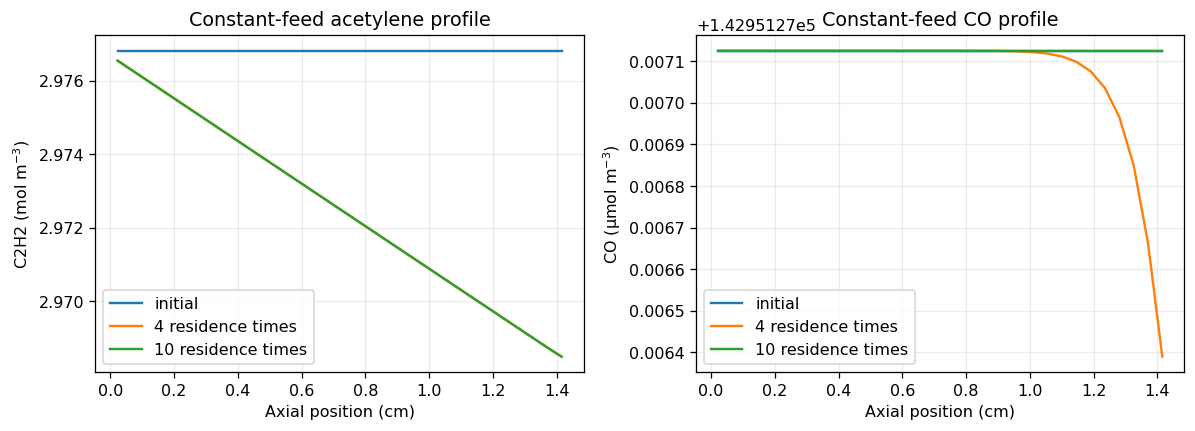

In [4]:
def initial_state(model):
    gas_in = np.asarray(model.inlet(0.0), dtype=float)
    bulk = np.tile(gas_in, (model.layout.n_z, 1))
    theta_eq = model.rate.coverages(gas_in * R_GAS * T_K, T_K)
    theta = np.tile(theta_eq, (model.layout.n_z, 1, 1))
    return model.layout.pack(bulk, theta=theta)

steady_t_end = 10.0 * GAS_RESIDENCE_S
steady_t_eval = np.linspace(0.0, steady_t_end, 81)
steady_solution = model.integrate(
    initial_state(model),
    (0.0, steady_t_end),
    method="BDF",
    rtol=2.0e-6,
    atol=1.0e-12,
    max_step=GAS_RESIDENCE_S / 20.0,
    t_eval=steady_t_eval,
)
if not steady_solution.success:
    raise RuntimeError(steady_solution.message)
steady_state = steady_solution.y[:, -1].copy()
one_residence_samples = max(1, int(round(GAS_RESIDENCE_S / (steady_t_eval[1] - steady_t_eval[0]))))
prior_state = steady_solution.y[:, -1 - one_residence_samples]
gas_scale = max(float(np.max(c_in)), 1e-12)
gas_profile_change = float(np.max(np.abs(steady_state[:model.layout.gas_size] - prior_state[:model.layout.gas_size])) / gas_scale)
surface_profile_change = float(np.max(np.abs(steady_state[model.layout.gas_size:] - prior_state[model.layout.gas_size:])))
steady_rhs = model.rhs(steady_t_end, steady_state)
scaled_steady_rhs = float(np.max(np.abs(EPS_B * steady_rhs[:model.layout.gas_size])) / gas_scale * GAS_RESIDENCE_S)
print({
    "integration time (s)": steady_t_end,
    "residence times": steady_t_end / GAS_RESIDENCE_S,
    "relative gas-profile change over last residence time": gas_profile_change,
    "absolute coverage change over last residence time": surface_profile_change,
    "dimensionless final bulk RHS": scaled_steady_rhs,
    "BDF function evaluations": int(steady_solution.nfev),
})
assert gas_profile_change < 2.0e-2
assert surface_profile_change < 2.0e-2

z_cm = (np.arange(model.layout.n_z) + 0.5) * model.derived.dz * 100.0
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
for label, sample_index in (("initial", 0), ("4 residence times", 32), ("10 residence times", -1)):
    bulk_profile = steady_solution.y[:model.layout.gas_size, sample_index].reshape(model.layout.n_z, len(GASES))
    axes[0].plot(z_cm, bulk_profile[:, IGAS["C2H2"]], label=label)
    axes[1].plot(z_cm, bulk_profile[:, IGAS["CO"]] * 1e6, label=label)
axes[0].set(xlabel="Axial position (cm)", ylabel="C2H2 (mol m$^{-3}$)", title="Constant-feed acetylene profile")
axes[1].set(xlabel="Axial position (cm)", ylabel="CO (µmol m$^{-3}$)", title="Constant-feed CO profile")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


## 4. Periodic inlet wave propagation and limit cycles

The square-wave integration is split at every half-cycle so BDF does not step across an inlet discontinuity. The sinusoidal case uses the same periodic hook with a smooth sine. Each case advances until two successive cycles agree in both gas and coverage states, up to a 12-cycle cap.

In [5]:
def bulk_history(model, y_history):
    return np.transpose(
        y_history[:model.layout.gas_size].reshape(model.layout.n_z, len(GASES), -1),
        (2, 0, 1),
    )

def metrics_from_cycle(model, t_cycle, y_cycle):
    bulk = bulk_history(model, y_cycle)
    outlet = bulk[:, -1, :]
    inlet = np.asarray(model.inlet(0.0), dtype=float)
    c_a_in = inlet[IGAS["C2H2"]]
    c_e_in = inlet[IGAS["C2H4"]]
    x = 1.0 - outlet[:, IGAS["C2H2"]] / c_a_in
    consumed = c_a_in - outlet[:, IGAS["C2H2"]]
    s = np.divide(
        outlet[:, IGAS["C2H4"]] - c_e_in,
        consumed,
        out=np.full_like(consumed, np.nan),
        where=np.abs(consumed) > 1e-10 * c_a_in,
    )
    x_bar = float(np.trapezoid(x, t_cycle) / (t_cycle[-1] - t_cycle[0]))
    s_bar = float(np.trapezoid(s, t_cycle) / (t_cycle[-1] - t_cycle[0]))
    return bulk, outlet, x, s, x_bar, s_bar

def integrate_one_cycle(model, y0, t_start, period_s, waveform, samples=40):
    inlet = periodic_co_inlet(
        operating,
        mean_ppm=Y_CO_MEAN * 1e6,
        delta_ppm=CO_DELTA_PPM,
        period_s=period_s,
        waveform=waveform,
    )
    if waveform == "sinusoidal":
        periodic_model = replace(model, inlet=inlet)
        t_eval = np.linspace(t_start, t_start + period_s, samples + 1)
        solution = periodic_model.integrate(
            y0, (t_start, t_start + period_s), method="BDF", rtol=2e-6,
            atol=1e-12, max_step=period_s / 40.0, t_eval=t_eval,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        return t_eval - t_start, solution.y

    high_inlet = inlet(t_start + 0.25 * period_s)
    low_inlet = inlet(t_start + 0.75 * period_s)
    half_models = [
        replace(model, inlet=lambda _t, value=value: value)
        for value in (high_inlet, low_inlet)
    ]
    times = []
    states = []
    state = y0
    for half, half_model in enumerate(half_models):
        left = t_start + half * period_s / 2.0
        right = t_start + (half + 1) * period_s / 2.0
        t_eval = np.linspace(left, right, samples // 2 + 1)
        solution = half_model.integrate(
            state, (left, right), method="BDF", rtol=2e-6, atol=1e-12,
            max_step=period_s / 40.0, t_eval=t_eval,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        keep = slice(None) if half == 0 else slice(1, None)
        times.extend((t_eval[keep] - t_start).tolist())
        states.append(solution.y[:, keep])
        state = solution.y[:, -1].copy()
    return np.asarray(times), np.concatenate(states, axis=1)

def run_periodic_case(model, period_s, waveform, max_cycles=20, tolerance=2.0e-3):
    state = steady_state.copy()
    previous_cycle = None
    cycle_change = np.inf
    for cycle in range(max_cycles):
        t_cycle, y_cycle = integrate_one_cycle(
            model, state, cycle * period_s, period_s, waveform
        )
        if previous_cycle is not None:
            gas_change = np.max(np.abs(y_cycle[:model.layout.gas_size] - previous_cycle[:model.layout.gas_size])) / gas_scale
            theta_change = np.max(np.abs(y_cycle[model.layout.gas_size:] - previous_cycle[model.layout.gas_size:]))
            cycle_change = float(max(gas_change, theta_change))
            if cycle_change < tolerance:
                break
        previous_cycle = y_cycle
        state = y_cycle[:, -1].copy()
    bulk, outlet, x, s, x_bar, s_bar = metrics_from_cycle(model, t_cycle, y_cycle)
    return {
        "period_s": period_s,
        "waveform": waveform,
        "t": t_cycle,
        "y": y_cycle,
        "bulk": bulk,
        "outlet": outlet,
        "X": x,
        "S": s,
        "X_bar": x_bar,
        "S_bar": s_bar,
        "cycles": cycle + 1,
        "cycle_change": cycle_change,
        "converged": bool(cycle_change < tolerance),
    }

dynamic_runs = {}
for waveform in ("square", "sinusoidal"):
    for period_s in CO_PERIODS_S:
        dynamic_runs[(waveform, float(period_s))] = run_periodic_case(
            model, float(period_s), waveform
        )

dynamic_rows = [
    {
        "waveform": result["waveform"],
        "period (s)": result["period_s"],
        "cycles integrated": result["cycles"],
        "limit-cycle converged": result["converged"],
        "cycle mismatch": result["cycle_change"],
        "mean conversion (%)": 100.0 * result["X_bar"],
        "mean ethylene selectivity (%)": 100.0 * result["S_bar"],
    }
    for result in dynamic_runs.values()
]
dynamic_frame = pd.DataFrame(dynamic_rows)
assert dynamic_frame["limit-cycle converged"].all()
display(dynamic_frame.round(4))


,waveform,period (s),cycles integrated,limit-cycle converged,cycle mismatch,mean conversion (%),mean ethylene selectivity (%)
0,square,0.1,4,True,0.0018,0.2793,88.1126
1,square,0.3,6,True,0.0020,0.2793,88.1126
2,square,1.0,13,True,0.0019,0.2828,88.1123
3,square,3.0,7,True,0.0002,0.3206,88.1090
4,square,10.0,4,True,0.0000,0.5915,88.0891
5,sinusoidal,0.1,3,True,0.0015,0.2793,88.1126
6,sinusoidal,0.3,5,True,0.0016,0.2793,88.1126
7,sinusoidal,1.0,10,True,0.0019,0.2756,88.1128
8,sinusoidal,3.0,7,True,0.0002,0.3028,88.1107
9,sinusoidal,10.0,4,True,0.0000,0.4533,88.0998


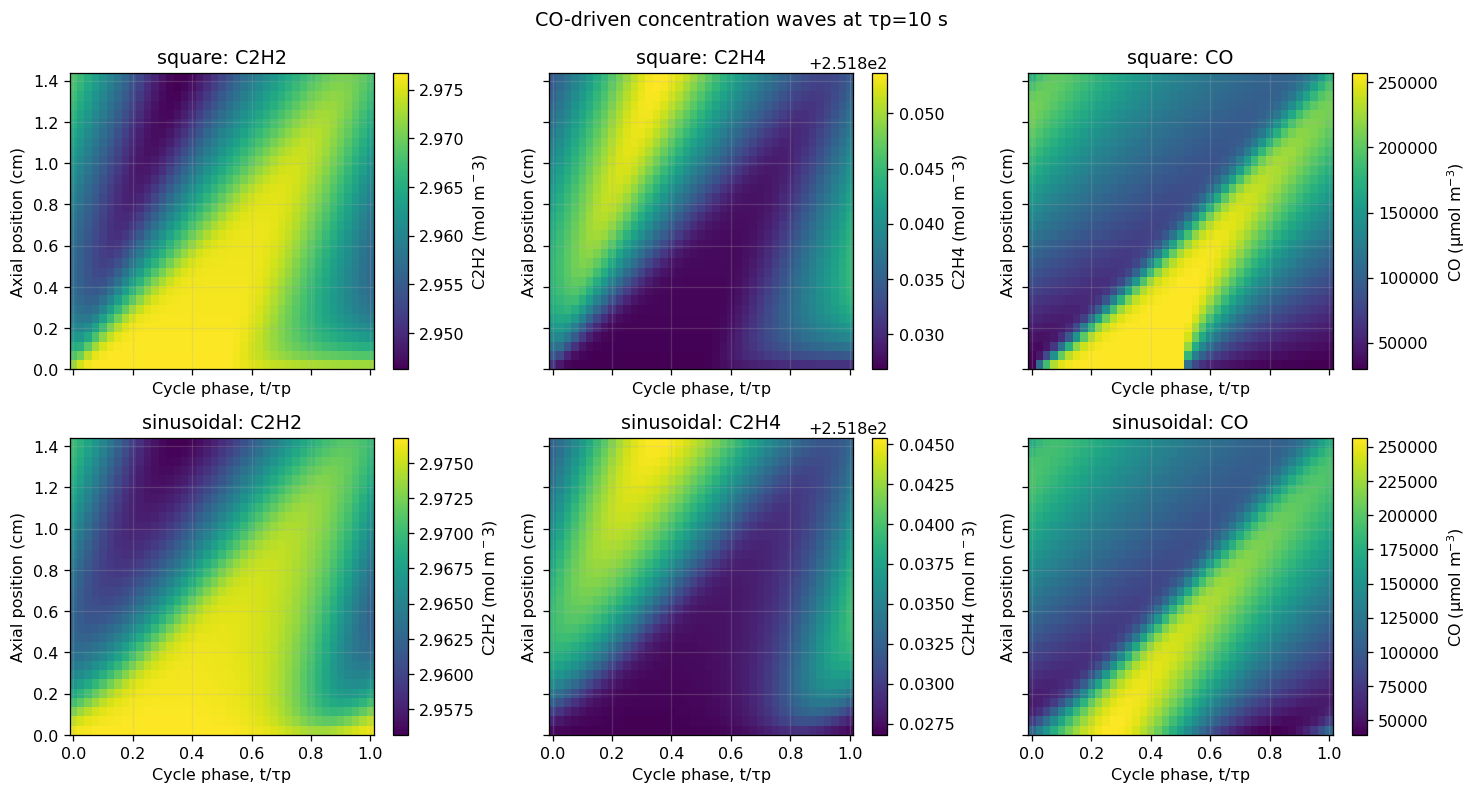

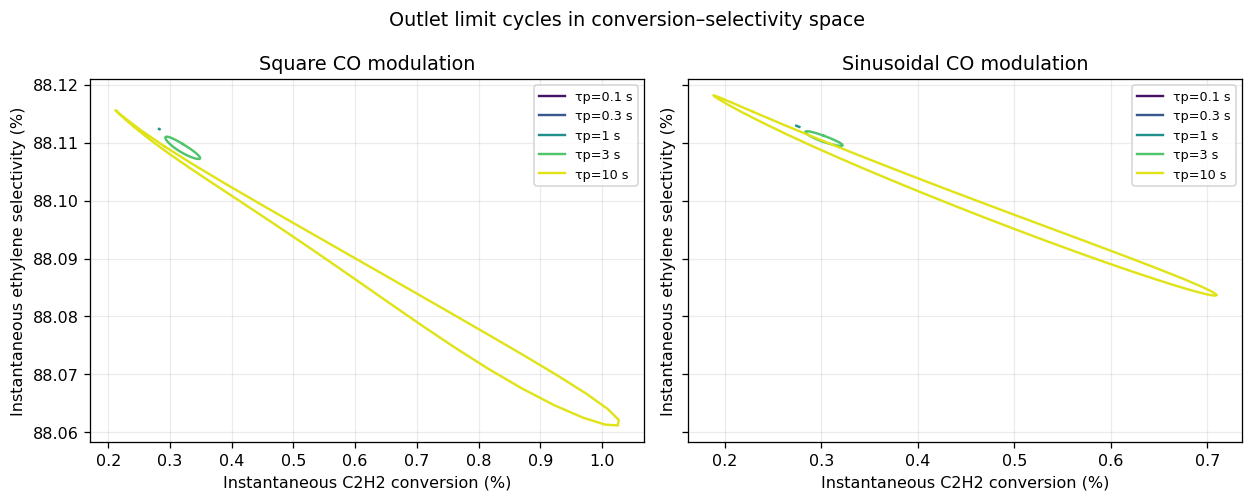

In [6]:
# Two-dimensional concentration fields over the final cycle at tau_p=10 s.
fig, axes = plt.subplots(2, 3, figsize=(13.0, 7.0), sharex=True, sharey=True)
heat_species = ["C2H2", "C2H4", "CO"]
for row, waveform in enumerate(("square", "sinusoidal")):
    result = dynamic_runs[(waveform, 10.0)]
    phase = result["t"] / result["period_s"]
    for col, species in enumerate(heat_species):
        values = result["bulk"][:, :, IGAS[species]].T
        if species == "CO":
            values = values * 1e6
            color_label = "CO (µmol m$^{-3}$)"
        else:
            color_label = f"{species} (mol m$^{-3}$)"
        image = axes[row, col].pcolormesh(
            phase, z_cm, values, shading="auto", cmap="viridis"
        )
        axes[row, col].set_title(f"{waveform}: {species}")
        axes[row, col].set_xlabel("Cycle phase, t/τp")
        axes[row, col].set_ylabel("Axial position (cm)")
        fig.colorbar(image, ax=axes[row, col], label=color_label)
fig.suptitle("CO-driven concentration waves at τp=10 s")
fig.tight_layout()
plt.show()

# Outlet limit cycles: instantaneous acetylene conversion vs net ethylene selectivity.
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4), sharey=True)
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(CO_PERIODS_S)))
for ax, waveform in zip(axes, ("square", "sinusoidal")):
    for color, period_s in zip(colors, CO_PERIODS_S):
        result = dynamic_runs[(waveform, float(period_s))]
        ax.plot(100.0 * result["X"], 100.0 * result["S"], color=color,
                label=f"τp={period_s:g} s")
    ax.set(title=f"{waveform.capitalize()} CO modulation",
           xlabel="Instantaneous C2H2 conversion (%)",
           ylabel="Instantaneous ethylene selectivity (%)")
    ax.legend(fontsize=8)
fig.suptitle("Outlet limit cycles in conversion–selectivity space")
fig.tight_layout()
plt.show()


## 5. Static ceiling and time-averaged Pareto comparison

The static reference scans constant CO from 0 to 500 ppm, settling each case with the same transient model. Its upper convex hull is the steady-operation ceiling when mixtures of static operating points are allowed. Periodic points are compared with that envelope; an improvement is claimed only when the computed cycle average lies outside it.

,waveform,period (s),mean conversion (%),mean ethylene selectivity (%),static hull S at X,distance above hull (pp S) =,cycle mismatch
0,square,0.1,0.279315,88.112596,0.881126,0.000000,0.001756
1,square,0.3,0.279315,88.112596,0.881126,-0.000000,0.001955
2,square,1.0,0.282792,88.112349,0.881124,-0.000031,0.001897
3,square,3.0,0.320613,88.109047,0.881100,-0.000978,0.000238
4,square,10.0,0.591526,88.089147,0.880931,-0.003980,0.000000
5,sinusoidal,0.1,0.279315,88.112596,0.881126,0.000000,0.001519
6,sinusoidal,0.3,0.279315,88.112596,0.881126,0.000000,0.001624
7,sinusoidal,1.0,0.275634,88.112824,0.881128,-0.000001,0.001922
8,sinusoidal,3.0,0.302782,88.110674,0.881111,-0.000461,0.000181
9,sinusoidal,10.0,0.453320,88.099761,0.881018,-0.001995,0.000000


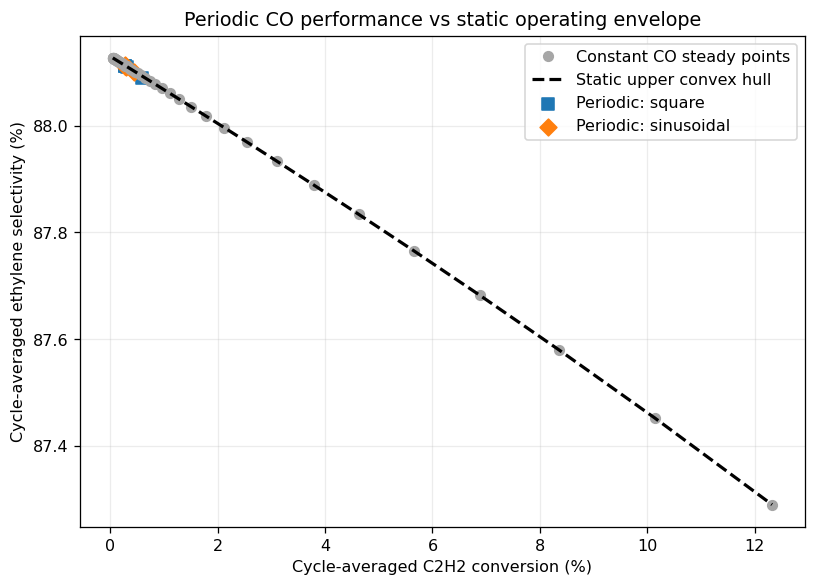

No periodic cycle average exceeds the sampled static hull by the 0.05 pp selectivity reporting threshold.
Maximum sampled-hull margin across periodic cases (positive means above): 8.88822e-10 pp selectivity.


In [7]:
def outlet_metrics_from_state(model, state):
    bulk, _, _ = model.layout.unpack(state)
    c_in = np.asarray(model.inlet(0.0), dtype=float)
    c_out = bulk[-1]
    x = 1.0 - c_out[IGAS["C2H2"]] / c_in[IGAS["C2H2"]]
    consumed = c_in[IGAS["C2H2"]] - c_out[IGAS["C2H2"]]
    selectivity = (
        (c_out[IGAS["C2H4"]] - c_in[IGAS["C2H4"]]) / consumed
        if abs(consumed) > 1e-10 * c_in[IGAS["C2H2"]]
        else np.nan
    )
    return float(x), float(selectivity)

static_rows = []
for co_ppm in np.linspace(0.0, 500.0, 51):
    static_inlet = periodic_co_inlet(
        operating, mean_ppm=float(co_ppm), delta_ppm=0.0,
        period_s=1.0, waveform="square",
    )
    static_model = replace(model, inlet=static_inlet)
    static_solution = static_model.integrate(
        steady_state,
        (0.0, 10.0 * GAS_RESIDENCE_S),
        method="BDF", rtol=2e-6, atol=1e-12,
        max_step=GAS_RESIDENCE_S / 10.0,
        t_eval=[10.0 * GAS_RESIDENCE_S],
    )
    if not static_solution.success:
        raise RuntimeError(static_solution.message)
    x_static, s_static = outlet_metrics_from_state(static_model, static_solution.y[:, -1])
    static_rows.append({"CO (ppm)": co_ppm, "X": x_static, "S": s_static})
static_frame = pd.DataFrame(static_rows).dropna().sort_values("X")

def upper_convex_hull(frame):
    points = frame[["X", "S"]].drop_duplicates().sort_values("X").to_numpy()
    hull = []
    for point in points:
        while len(hull) >= 2:
            x0, y0 = hull[-2]
            x1, y1 = hull[-1]
            slope_previous = (y1 - y0) / max(x1 - x0, 1e-15)
            slope_next = (point[1] - y1) / max(point[0] - x1, 1e-15)
            if slope_next >= slope_previous:
                hull.pop()
            else:
                break
        hull.append(point)
    return np.asarray(hull)

static_hull = upper_convex_hull(static_frame)
dynamic_frame["X_bar"] = dynamic_frame["mean conversion (%)"] / 100.0
dynamic_frame["S_bar"] = dynamic_frame["mean ethylene selectivity (%)"] / 100.0
dynamic_frame["static hull S at X"] = np.nan
dynamic_frame["distance above hull (pp S) ="] = np.nan
for idx, row in dynamic_frame.iterrows():
    x = row["X_bar"]
    if static_hull[0, 0] <= x <= static_hull[-1, 0]:
        hull_s = float(np.interp(x, static_hull[:, 0], static_hull[:, 1]))
        dynamic_frame.loc[idx, "static hull S at X"] = hull_s
        dynamic_frame.loc[idx, "distance above hull (pp S) ="] = 100.0 * (row["S_bar"] - hull_s)

display(dynamic_frame[[
    "waveform", "period (s)", "mean conversion (%)",
    "mean ethylene selectivity (%)", "static hull S at X",
    "distance above hull (pp S) =", "cycle mismatch",
]].round(6))

fig, ax = plt.subplots(figsize=(7.2, 5.2))
ax.plot(100.0 * static_frame["X"], 100.0 * static_frame["S"], "o",
        color="0.65", label="Constant CO steady points")
ax.plot(100.0 * static_hull[:, 0], 100.0 * static_hull[:, 1], "k--",
        linewidth=2, label="Static upper convex hull")
for waveform, marker in (("square", "s"), ("sinusoidal", "D")):
    rows = dynamic_frame[dynamic_frame["waveform"] == waveform]
    ax.scatter(rows["mean conversion (%)"], rows["mean ethylene selectivity (%)"],
               marker=marker, s=55, label=f"Periodic: {waveform}")
ax.set(xlabel="Cycle-averaged C2H2 conversion (%)",
       ylabel="Cycle-averaged ethylene selectivity (%)",
       title="Periodic CO performance vs static operating envelope")
ax.legend()
fig.tight_layout()
plt.show()

inside = dynamic_frame[dynamic_frame["distance above hull (pp S) ="].notna()]
beyond = inside[inside["distance above hull (pp S) ="] > 5e-2]
if not beyond.empty:
    print("Cycle averages above the sampled static convex hull:")
    display(beyond[["waveform", "period (s)", "mean conversion (%)",
                    "mean ethylene selectivity (%)", "distance above hull (pp S) ="]].round(4))
else:
    print(
        "No periodic cycle average exceeds the sampled static hull by the "
        "0.05 pp selectivity reporting threshold."
    )
if not inside.empty:
    print(
        "Maximum sampled-hull margin across periodic cases "
        f"(positive means above): {inside['distance above hull (pp S) ='].max():.6g} pp selectivity."
    )


## 6. Surface-timescale sensitivity and interpretation

The surface relaxation time is not reported in Schbib et al. A small sweep at τp=1 s shows whether the transient conclusions depend on the assumed surface-memory timescale. This sensitivity is required before interpreting a Pareto shift as a physical operating recommendation.

In [8]:
tau_sweep_rows = []
for tau_s in (0.01, 0.05, 0.2, 1.0):
    _, tau_model = build_case(surface_tau_s=tau_s)
    # The steady gas/coverage profile is independent of the relaxation rate.
    tau_result = run_periodic_case(tau_model, 1.0, "square")
    tau_sweep_rows.append({
        "assumed surface tau (s)": tau_s,
        "cycle-averaged conversion (%)": 100.0 * tau_result["X_bar"],
        "cycle-averaged selectivity (%)": 100.0 * tau_result["S_bar"],
        "cycles": tau_result["cycles"],
        "cycle mismatch": tau_result["cycle_change"],
        "limit-cycle converged": tau_result["converged"],
    })
tau_sensitivity = pd.DataFrame(tau_sweep_rows)
assert tau_sensitivity["limit-cycle converged"].all()
display(tau_sensitivity.round(5))

print(f"Static scan range: X={100*static_frame['X'].min():.4f}–{100*static_frame['X'].max():.4f}%.")
print(f"Maximum cycle mismatch among requested wave cases: {dynamic_frame['cycle mismatch'].max():.4g}.")
print("Each sensitivity case uses its stated surface relaxation time.")
model_runtime_s = time.perf_counter() - NOTEBOOK_STARTED
print(f"Notebook model runtime: {model_runtime_s:.2f} s.")
assert model_runtime_s < 180.0


,assumed surface tau (s),cycle-averaged conversion (%),cycle-averaged selectivity (%),cycles,cycle mismatch,limit-cycle converged
0,0.01,0.28352,88.11230,13,0.00197,True
1,0.05,0.28279,88.11235,13,0.00190,True
2,0.20,0.27746,88.11271,11,0.00193,True
3,1.00,0.26454,88.11357,7,0.00168,True


Static scan range: X=0.0504–12.3194%.
Maximum cycle mismatch among requested wave cases: 0.001955.
Each sensitivity case uses its stated surface relaxation time.
Notebook model runtime: 13.67 s.


## Takeaways

The executed plots, steady-state convergence metrics, cycle mismatch, and static-hull comparison above are the evidence for the V4 results. For this parameterization, tested periodic cycle averages remain on the sampled static hull to numerical precision (maximum positive margin is reported above), so the requested Pareto-enhancement gate is not met. The shared CO-inhibition denominator in both Schbib rates and the assumed surface relaxation time limit the conclusions. The assumed pellet size, bed void fraction, and interpretation of the source's unbased `log A_i` add further physical uncertainty.